# 03 — Estimativa de evaporação (Penman, NASA POWER)
**Hipóteses e limites (leia antes dos números):**
- Meteorologia: **NASA POWER** (satélite/reanálise) no ponto da barragem (−6,24; −38,91), **não** INMET (acesso indisponível). Não substitui medições locais.
- Penman de água livre (albedo 0,08, termos de radiação FAO-56); **armazenamento de calor G ignorado**.
- Área do espelho: a curva cota–área **não foi obtida**. Usa-se `A = A_full·(V/1940)^k` como **suposição explícita**, explorada em faixa (A_full 150–250 km², k 0,5–0,8). Esses valores são premissas, não dados do Orós.
- `E = e·A` (mm × km² × 10⁻³ = hm³).

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data.loaders import load_portal_volume
from src.hydrology.evaporation import load_power, penman_open_water_mm, evaporation_hm3
from src.hydrology.water_balance import reconstruct_net_inflow

met = load_power('../data/raw/meteo/nasa_power_oros_daily.json')
met['E_mm_day'] = penman_open_water_mm(met)
vol = load_portal_volume('../data/reserv-ors-capac-175236-portal-hidrologico-ce.csv')
df = vol.merge(met[['date', 'E_mm_day']], on='date')
print(df.E_mm_day.describe().round(2))
print('Lâmina anual média (mm/ano), anos completos:', round(df[(df.date.dt.year > 2006) & (df.date.dt.year < 2026)].groupby(df.date.dt.year).E_mm_day.sum().mean()))

count    7302.00
mean        8.16
std         2.05
min         2.30
25%         6.48
50%         8.07
75%         9.95
max        13.04
Name: E_mm_day, dtype: float64
Lâmina anual média (mm/ano), anos completos: 2977


## 1. Sanidade
A lâmina anual obtida (~3.000 mm/ano) é **alta** para evaporação de lago no semiárido (valores típicos citados para o Nordeste ficam em ~1.800–2.500 mm/ano; **não verificado nesta pesquisa**). O Penman sem armazenamento de calor tende a superestimar. Trate E como **limite superior** até calibrar com dados locais (tanque classe A / Cogerh).

In [2]:
cases = {'baixo (150 km², k=0,8)': dict(a_full=150, k=0.8),
         'base (190 km², k=0,65)': dict(a_full=190, k=0.65),
         'alto (250 km², k=0,5)': dict(a_full=250, k=0.5)}
for n, kw in cases.items():
    df['E_' + n] = evaporation_hm3(df.E_mm_day, df.volume_hm3.fillna(df.volume_hm3.median()), **kw)
yr = df.groupby(df.date.dt.year)[[c for c in df if c.startswith('E_') and c != 'E_mm_day']].sum().round(0)
yr.loc[2007:2025]

,"E_baixo (150 km², k=0,8)","E_base (190 km², k=0,65)","E_alto (250 km², k=0,5)"
date,,,
2007,307.0,417.0,589.0
2008,345.0,453.0,618.0
2009,351.0,457.0,617.0
2010,346.0,460.0,634.0
2011,351.0,458.0,621.0
2012,397.0,524.0,717.0
2013,286.0,397.0,571.0
2014,255.0,360.0,528.0
2015,210.0,311.0,478.0


## 2. Consistência com a reconstrução de 02
Em meses secos (ago–nov, **suposição** de afluência ≈ 0 para a região), `−I_net` ≈ `E + (R_real − 5,3 m³/s)`. O resíduo `−I_net − E` estima então `R_real − R_assumido` (+ infiltração/erro). Se o resíduo for sistematicamente grande, ou E está superestimada ou a retirada real difere muito de 5,3 m³/s.

In [3]:
r = reconstruct_net_inflow(vol, 5.3); r = r[r.valid].merge(df[['date', 'E_mm_day', 'volume_hm3']], on='date')
E = 'E_base (190 km², k=0,65)'
r['E_hm3'] = evaporation_hm3(r.E_mm_day, r.v0, a_full=190, k=0.65)
dry = r[r.date.dt.month.isin([8, 9, 10, 11])].copy(); dry['y'] = dry.date.dt.year
t = dry.groupby('y').agg(dias=('I_net_hm3', 'size'), nI_net=('I_net_hm3', 'mean'), E=('E_hm3', 'mean'))
t['residuo_hm3_dia'] = -t.nI_net - t.E
t['residuo_m3s'] = t.residuo_hm3_dia / 0.0864
t.round(3)

,dias,nI_net,E,residuo_hm3_dia,residuo_m3s
y,,,,,
2006,29,-1.090,1.471,-0.381,-4.410
2007,122,-1.154,1.456,-0.302,-3.493
2008,122,-1.292,1.665,-0.373,-4.312
2009,105,-1.260,1.686,-0.426,-4.927
2010,122,-1.049,1.465,-0.416,-4.819
2011,119,-0.821,1.659,-0.838,-9.697
2012,122,-1.491,1.630,-0.139,-1.609
2013,118,-0.974,1.211,-0.238,-2.751
2014,122,-0.804,1.167,-0.363,-4.204


Resíduo mediano (m³/s): -4.41 | intervalo: -9.7 a 0.89


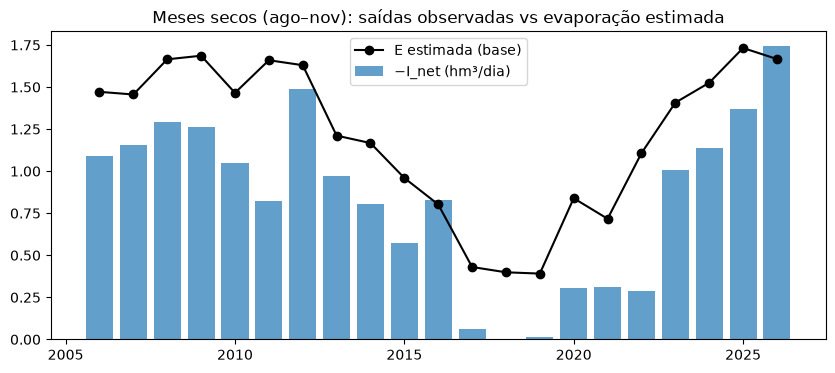

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(t.index, -t.nI_net, label='−I_net (hm³/dia)', alpha=.7); ax.plot(t.index, t.E, 'ko-', label='E estimada (base)')
ax.set_title('Meses secos (ago–nov): saídas observadas vs evaporação estimada'); ax.legend()
fig.savefig('../results/figures/03_dry_season_outflow_vs_E.png', dpi=150, bbox_inches='tight')
print('Resíduo mediano (m³/s):', round(t.residuo_m3s.median(), 2), '| intervalo:', round(t.residuo_m3s.min(), 2), 'a', round(t.residuo_m3s.max(), 2))

## 3. Leitura
Ver o resultado da célula acima. O resíduo mistura erro de E, erro de A(V), retirada real ≠ 5,3 m³/s, infiltração, afluência residual e ruído de medição: **não é identificável com estes dados**. Para separar os componentes são necessários a curva cota–área e as retiradas reais (Cogerh).